# Лабораторная работа №2

In [1]:
from pathlib import Path
from html import escape
from IPython.display import display, HTML
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN

from lab2.preprocessing import load_texts, preprocess_texts
from lab2.word_count import lemmatize_texts, count_lemmas, save_word_counts
from lab2.clustering import (
    build_features, cluster_documents, build_cluster_tables,
    plot_clusters, save_results,
)

## Параметры эксперимента

In [2]:
INPUT = Path("inputs/posts.csv")
OUTPUT = Path("output/lab2")
KEEP_STOP_WORDS = False
MIN_DF = 2 # Минимальное число документов с термином
MAX_DF = 0.9 # Максимальная доля документов с термином
MAX_FEATURES = 5000
NGRAM_RANGE = (1, 2) # Леммы и пары соседних лемм после фильтрации
ALGORITHMS = {
    "KMeans": KMeans(random_state=42, n_init=20),
    "MiniBatchKMeans": MiniBatchKMeans(random_state=42, n_init=20, batch_size=256),
    "Agglomerative": AgglomerativeClustering(metric="cosine", linkage="average")
}
MAX_CLUSTERS = 8 # Проверяем k от 2 до min(MAX_CLUSTERS, n - 1)
RESULT_FILES = ("clusters.csv", "cluster_sizes.csv", "comparison.csv", "clusters.png")

In [3]:
def show_table(rows):
    """Отображение таблиц внутри notebook без создания файлов"""
    if not rows:
        print("Нет строк для отображения")
        return
    headers = list(rows[0])
    head = "".join(f"<th>{escape(str(key))}</th>" for key in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(row[key]))}</td>" for key in headers) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

## Задание 1. Предобработка
Загрузка поля `text`, очистка ссылок и спецсимволов, нижний регистр, удаление пустых текстов и дубликатов. Индексы далее относятся к очищенному корпусу, а не к ID постов VK.

In [4]:
raw_texts = load_texts(INPUT)
texts = preprocess_texts(raw_texts)
print(f"Загружено: {len(raw_texts)}; осталось после очистки: {len(texts)}")
show_table([{"document_index": i, "text": text} for i, text in enumerate(texts[:3])])

Загружено: 40; осталось после очистки: 40


document_index,text
0,внимание открытие ботанического сада самарского университета им королева запланированное на августа откладывается до завершения всех работ приносим извинения за временные неудобства о дате открытия сообщим дополнительно
1,выпускники химических направлений университета вошли в число самых высокооплачиваемых в стране исследовательский центр superjob представил свежий рейтинг университетов россии с профильными химическими химико технологическими инженерно химическими и фармацевтическими направлениями подготовки специалистов в году в рейтинг попал самарский национальный исследовательский университет имени академика с п королёва он включен в топ рейтинга эксперты отнесли вуз на позицию по данным исследования средняя зарплата молодых людей с дипломом самарского университета им королёва в данных сферах окончивших вуз в годах составила рублей при этом составители рейтинга указывают что выпускников университета окончивших вуз в этот период остались работать в самарской области подробнее на сайте
2,завтра августа в закрывается окно возможности получить новый опыт с по августа клуб водного туризма самарского университета им королёва проводит учебно тренировочные сборы по водному туризму и гребному слалому условия опыт не требуется участие бесплатно всё специальное снаряжение необходимое для участия предоставляет клуб проживание в палатках приготовление пищи на костре требований к физической форме и навыкам участников нет главное желание записывайтесь по телефону до августа сборы пройдут в тимашево а в этом суданец мазин поделился впечатлениями которые получил от своего первого прохождения водопада на каяке


## Задание 2. Частотный словарь
PyMorphy3 приводит слова к начальной форме. По умолчанию исключаются PREP, CONJ, PRCL, NPRO, INTJ. Выбирается первый разбор без контекста, поэтому возможны ошибки на неоднозначных словах. Повторения слов сохраняются.

In [5]:
documents = lemmatize_texts(texts, keep_stop_words=KEEP_STOP_WORDS)
counts = count_lemmas(documents)
print(f"Уникальных лемм: {len(counts)}; вхождений: {sum(counts.values())}")
show_table([{"word": word, "count": count} for word, count in sorted(counts.items(), key=lambda item: (-item[1], item[0]))[:20]])

Уникальных лемм: 1824; вхождений: 3936


word,count
университет,87
самарский,47
студент,36
который,31
год,29
наш,29
проект,27
программа,24
королёв,23
новый,22


## Задание 3. Подготовка признаков
TF-IDF: обычная частота TF, сглаженный IDF, L2-нормализация строк. Каждый пост — отдельный документ.

In [6]:
matrix, vectorizer = build_features(
    documents, min_df=MIN_DF, max_df=MAX_DF,
    max_features=MAX_FEATURES, ngram_range=NGRAM_RANGE,
)
print(f"Матрица: {matrix.shape[0]} документов × {matrix.shape[1]} признаков")
print(f"Документов без признаков: {(matrix.getnnz(axis=1) == 0).sum()}")

Матрица: 40 документов × 682 признаков
Документов без признаков: 0


### Сравнение алгоритмов

In [7]:
results, comparisons = cluster_documents(matrix, algorithms=ALGORITHMS, max_clusters=MAX_CLUSTERS)
show_table(comparisons)

algorithm,requested_clusters,actual_clusters,noise_count,silhouette_cosine,selected
KMeans,2,2,0,0.03477200821056941,False
KMeans,3,3,0,0.025122735105847577,False
KMeans,4,4,0,0.040395580304971236,False
KMeans,5,5,0,0.03354223089482492,False
KMeans,6,6,0,0.04703650195060702,False
KMeans,7,7,0,0.03817331796854263,False
KMeans,8,8,0,0.0646473466622303,True
MiniBatchKMeans,2,2,0,0.03107177580911654,False
MiniBatchKMeans,3,3,0,-0.005562153450706593,False
MiniBatchKMeans,4,4,0,0.01477888518112327,False


### Распределение постов и размеры кластеров
Номера кластеров разных алгоритмов не обозначают одинаковые темы. Ключевые термины — семь признаков с наибольшим средним TF-IDF в кластере.

In [8]:
assignments, sizes = build_cluster_tables(texts, matrix, vectorizer, results)
show_table(sizes)

algorithm,cluster,document_count,top_terms
KMeans,0,6,"почему, помогать, ничего, который, наш, ценность, клуб"
KMeans,1,9,"университет, программа, год, самарский, развитие, проект, студент"
KMeans,2,2,"александр, фетисов, самарский, рабочий, рабочий встреча, илья, лейковский"
KMeans,3,5,"институт, факультет, первокурсник, олимпиада, участник, прийти, студенческий"
KMeans,4,8,"команда, проект, разработка, этот, один, кафедра, который"
KMeans,5,2,"регион, наследие, карточка, история, объект, страница, наследие самарский"
KMeans,6,4,"сад, ботанический, ботанический сад, ботсад, поступление, сад самарский, открытие"
KMeans,7,4,"андрей, рф, студент, стипендиат, стипендия, экономика, мочь"
MiniBatchKMeans,0,1,"открытие, университет королева, запланировать, сообщить, сад самарский, внимание, королева"
MiniBatchKMeans,1,6,"самарский, центр, август, университет, который, туризм, самарский университет"


### Визуализация
Все методы показаны в одной проекции PCA. Кластеризация выполнялась по всем признакам; рисунок теряет часть информации. Сохранённая доля дисперсии указана в заголовке.

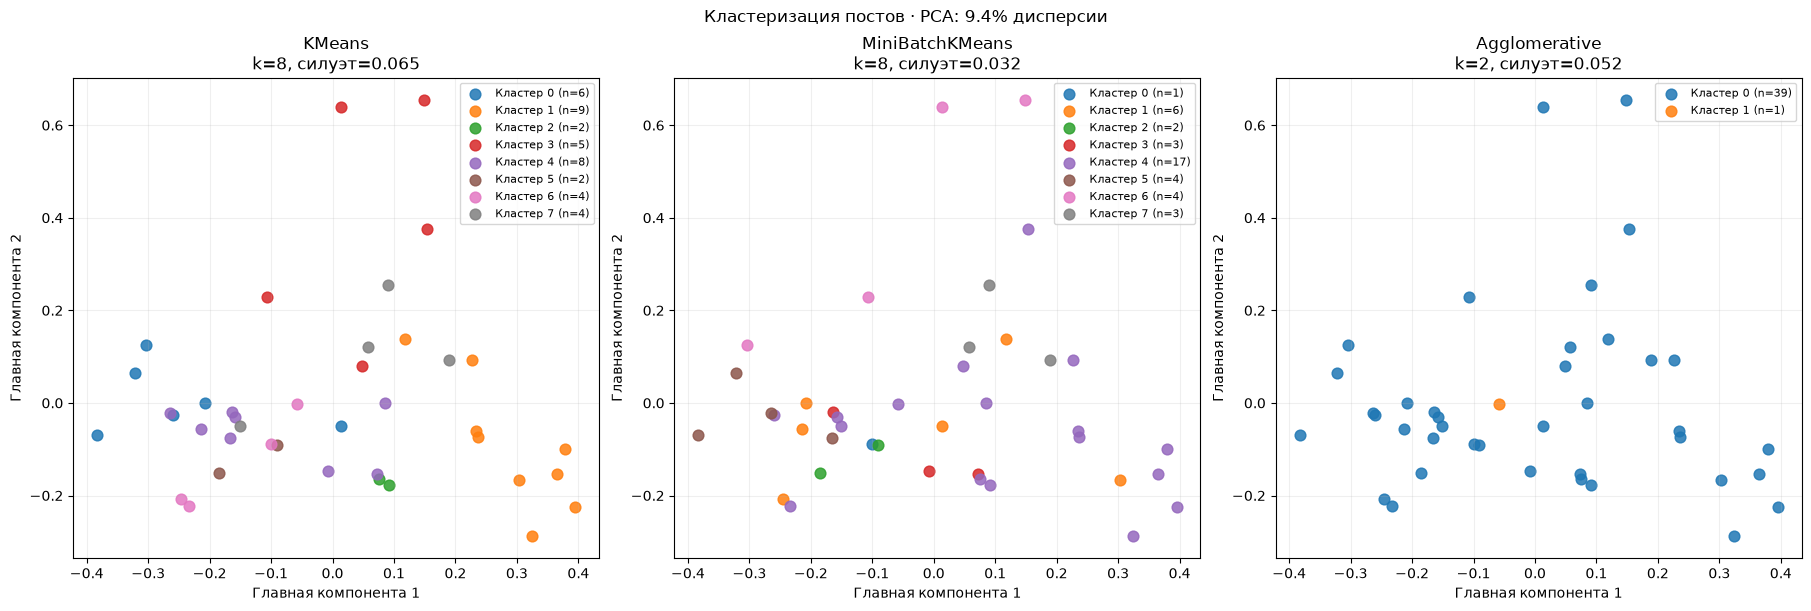

In [9]:
figure = plot_clusters(matrix, results)
display(figure)
plt.close(figure)

## Сохранение итоговых результатов

In [10]:
save_word_counts(counts, OUTPUT / "word_counts.csv")
save_results(OUTPUT, assignments, sizes, comparisons, figure)
print("Сохранены итоговые файлы:")
for name in ("word_counts.csv", *RESULT_FILES):
    print(OUTPUT / name)

Сохранены итоговые файлы:
output\lab2\word_counts.csv
output\lab2\clusters.csv
output\lab2\cluster_sizes.csv
output\lab2\comparison.csv
output\lab2\clusters.png
